# Direction evaluation across all videos

For every GT event in every annotation CSV that has a matching video in
`ground_truth_annotations/data/`, runs `direction_predict.predict_direction`
on the GT span and compares against the labelled direction.

Produces a single consolidated CSV + a single metrics file:

- `outputs/optical-flow/direction_only/all_videos_direction.csv`
- `outputs/optical-flow/direction_only/all_videos_metrics.json`

Uses only `predict_direction` + `df.apply`. No full-video Farneback pass --
only the frames inside each GT span are processed, so the compute cost scales
with total event duration (typically a small fraction of each video).

Set `MAX_PARALLEL_VIDEOS` below to dispatch multiple videos to parallel
worker processes. `2` is a safe default on an 8-core box.


## 1. Setup + auto-discover video / annotation pairs

In [1]:
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed
import re
import json
import pandas as pd
import matplotlib.pyplot as plt

import direction_predict as dp

REPO       = Path('..') / '..'
DATA_DIR   = REPO / 'ground_truth_annotations' / 'data'
ANNOTS_DIR = REPO / 'ground_truth_annotations' / 'finalized_annotations'
OUT_DIR    = REPO / 'outputs' / 'optical-flow' / 'direction_only'
OUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_PARALLEL_VIDEOS = 2   # process this many videos concurrently
PREDICT_CFG = dict(frame_stride=2, downsample=2.0, crop_frac=0.1,
                    mag_thr=0.5, blur_ksize=3, activity_thr=50)

def _find_annotation_file(video_path, annots_dir):
    """Match a video file to its annotation CSV by extracting the leading
    video number (and day, if present) from the stem."""
    stem = video_path.stem
    m_num = re.match(r'(\d+)', stem)
    if not m_num:
        return None
    vid_num = int(m_num.group(1))
    m_day = re.search(r'day(\d+)', stem, re.IGNORECASE)
    day = int(m_day.group(1)) if m_day else None
    candidates = []
    if day is not None:
        candidates += [
            annots_dir / f'circling_annotations_vid{vid_num:04d}-day{day}.csv',
            annots_dir / f'circling_annotations_vid{vid_num:04d}-day{day:02d}.csv',
        ]
    candidates += [
        annots_dir / f'circling_annotations_vid{vid_num:04d}.csv',
        annots_dir / f'circling_annotations_vid{vid_num:03d}.csv',
    ]
    for c in candidates:
        if c.exists():
            return c
    for p in annots_dir.glob('*.csv'):
        if re.search(rf'\b0*{vid_num}\b', p.stem) or f'vid{vid_num:04d}' in p.stem:
            if day is None or f'day{day}' in p.stem.lower():
                return p
    return None

video_paths = sorted(DATA_DIR.glob('*.mp4'))
pairs = []
for v in video_paths:
    a = _find_annotation_file(v, ANNOTS_DIR)
    if a is None:
        print(f'[skip] no annotation for {v.name}')
        continue
    pairs.append((v, a))

print(f'discovered {len(pairs)} video/annotation pairs:')
for v, a in pairs:
    print(f'  {v.name}  ->  {a.name}')

discovered 8 video/annotation pairs:
  0002_vid.mp4  ->  circling_annotations_vid0002.csv
  0007_vid_day05.mp4  ->  circling_annotations_vid0007-day5.csv
  0007_vid_day06.mp4  ->  circling_annotations_vid0007-day6.csv
  0013_vid.mp4  ->  circling_annotations_vid013.csv
  0018_vid.mp4  ->  circling_annotations_vid0018.csv
  0028_vid.mp4  ->  circling_annotations_vid0028.csv
  0031_vid.mp4  ->  circling_annotations_vid0031.csv
  0037_vid.mp4  ->  circling_annotations_vid0037.csv


## 2. Predict direction for every GT event (parallel)

Each video is dispatched to a worker process running
`direction_predict.score_video_gt_events`, which internally applies
`predict_direction` to every row of the annotation CSV. Results are
concatenated as workers complete, then sorted for a stable row order.

In [2]:
all_frames = []
with ProcessPoolExecutor(max_workers=MAX_PARALLEL_VIDEOS) as ex:
    futures = {ex.submit(dp.score_video_gt_events, str(v), str(a), PREDICT_CFG): v.stem
               for v, a in pairs}
    print(f'dispatched {len(futures)} videos to {MAX_PARALLEL_VIDEOS} workers; '
          f'waiting for completions...')
    for fut in as_completed(futures):
        stem = futures[fut]
        try:
            df = fut.result()
        except Exception as e:
            print(f'[fail] {stem}: {type(e).__name__}: {e}')
            continue
        all_frames.append(df)
        scored = df.dropna(subset=['correct'])
        n, c = len(scored), int(scored['correct'].sum()) if len(scored) else 0
        tag = f'{c}/{n}  acc={c/n:.4f}' if n else 'no scored events'
        print(f'[done] {stem:20s}  {len(df):4d} events   {tag}')

combined = pd.concat(all_frames, ignore_index=True)
combined = combined.sort_values(['video', 'start_frame']).reset_index(drop=True)

combined_csv = OUT_DIR / 'all_videos_direction.csv'
combined.to_csv(combined_csv, index=False)
print(f'\nwrote: {combined_csv}')
print(f'rows: {len(combined)}  videos: {combined["video"].nunique()}')

dispatched 8 videos to 2 workers; waiting for completions...


/mnt/c/Users/thaku/OneDrive/Desktop/Rupak/OMSCS/CS8903-Biomedical AI/Cichlid project/HAAG repo/cichlid-analysis/models/optical-flow/direction_predict.py:186: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  out.loc[out['pred_direction'].isna(), 'correct'] = pd.NA


[done] 0002_vid                53 events   53/53  acc=1.0000


/mnt/c/Users/thaku/OneDrive/Desktop/Rupak/OMSCS/CS8903-Biomedical AI/Cichlid project/HAAG repo/cichlid-analysis/models/optical-flow/direction_predict.py:186: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  out.loc[out['pred_direction'].isna(), 'correct'] = pd.NA


[done] 0007_vid_day05         102 events   102/102  acc=1.0000


/mnt/c/Users/thaku/OneDrive/Desktop/Rupak/OMSCS/CS8903-Biomedical AI/Cichlid project/HAAG repo/cichlid-analysis/models/optical-flow/direction_predict.py:186: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  out.loc[out['pred_direction'].isna(), 'correct'] = pd.NA


... (7 outputs left out)

/mnt/c/Users/thaku/OneDrive/Desktop/Rupak/OMSCS/CS8903-Biomedical AI/Cichlid project/HAAG repo/cichlid-analysis/models/optical-flow/direction_predict.py:186: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  out.loc[out['pred_direction'].isna(), 'correct'] = pd.NA


[done] 0031_vid                64 events   64/64  acc=1.0000


/mnt/c/Users/thaku/OneDrive/Desktop/Rupak/OMSCS/CS8903-Biomedical AI/Cichlid project/HAAG repo/cichlid-analysis/models/optical-flow/direction_predict.py:186: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  out.loc[out['pred_direction'].isna(), 'correct'] = pd.NA


[done] 0037_vid               111 events   110/110  acc=1.0000

wrote: ../../outputs/optical-flow/direction_only/all_videos_direction.csv
rows: 659  videos: 8


## 3. Consolidated metrics

Confusion matrix + per-class precision / recall / F1 + overall accuracy.
Saves a single JSON summary alongside the CSV.

In [3]:
scored = combined.dropna(subset=['gt_direction', 'pred_direction'])
n_total   = len(combined)
n_scored  = len(scored)
n_correct = int(scored['correct'].sum())
accuracy  = n_correct / n_scored if n_scored else float('nan')

# Confusion matrix
conf = pd.crosstab(scored['gt_direction'], scored['pred_direction'],
                   rownames=['GT'], colnames=['Pred'], dropna=False)
conf = conf.reindex(index=['CW', 'CCW'], columns=['CW', 'CCW'], fill_value=0)

def _prf(tp, fp, fn):
    p = tp / (tp + fp) if (tp + fp) else float('nan')
    r = tp / (tp + fn) if (tp + fn) else float('nan')
    f = 2 * p * r / (p + r) if (p + r) else float('nan')
    return p, r, f

cw_tp  = int(conf.at['CW',  'CW']);  cw_fn  = int(conf.at['CW',  'CCW'])
ccw_tp = int(conf.at['CCW', 'CCW']); ccw_fn = int(conf.at['CCW', 'CW'])
cw_fp  = ccw_fn
ccw_fp = cw_fn
pcw, rcw, fcw     = _prf(cw_tp,  cw_fp,  cw_fn)
pccw, rccw, fccw  = _prf(ccw_tp, ccw_fp, ccw_fn)
macro_f1 = (fcw + fccw) / 2

summary = {
    'n_videos':          int(combined['video'].nunique()),
    'n_events_total':    int(n_total),
    'n_events_scored':   int(n_scored),
    'n_events_correct':  int(n_correct),
    'accuracy':          float(accuracy),
    'confusion_matrix': {
        'CW_as_CW':   cw_tp,
        'CW_as_CCW':  cw_fn,
        'CCW_as_CCW': ccw_tp,
        'CCW_as_CW':  ccw_fn,
    },
    'per_class': {
        'CW':  {'TP': cw_tp,  'FP': cw_fp,  'FN': cw_fn,
                'precision': pcw,  'recall': rcw,  'f1': fcw},
        'CCW': {'TP': ccw_tp, 'FP': ccw_fp, 'FN': ccw_fn,
                'precision': pccw, 'recall': rccw, 'f1': fccw},
    },
    'macro_f1': float(macro_f1),
    'micro_f1': float(accuracy),
}

per_video = {}
for stem, df_v in combined.groupby('video'):
    sv = df_v.dropna(subset=['gt_direction', 'pred_direction'])
    per_video[stem] = {
        'n_events_total':   int(len(df_v)),
        'n_events_scored':  int(len(sv)),
        'n_events_correct': int(sv['correct'].sum()),
        'accuracy':         float(sv['correct'].mean()) if len(sv) else None,
    }
summary['per_video'] = per_video

metrics_json = OUT_DIR / 'all_videos_metrics.json'
metrics_json.write_text(json.dumps(summary, indent=2))
print(f'wrote: {metrics_json}')

print('\n=== CONSOLIDATED METRICS ===')
print(f'videos: {summary["n_videos"]}   events scored: {n_scored}/{n_total}')
print(f'overall accuracy = {accuracy:.4f}')
print('\nconfusion matrix (rows=GT, cols=Pred):')
print(conf)
print(f'\nCW : TP={cw_tp:3d} FP={cw_fp:3d} FN={cw_fn:3d}  '
      f'P={pcw:.4f} R={rcw:.4f} F1={fcw:.4f}')
print(f'CCW: TP={ccw_tp:3d} FP={ccw_fp:3d} FN={ccw_fn:3d}  '
      f'P={pccw:.4f} R={rccw:.4f} F1={fccw:.4f}')
print(f'macro F1 = {macro_f1:.4f}   micro F1 = {accuracy:.4f}')

wrote: ../../outputs/optical-flow/direction_only/all_videos_metrics.json

=== CONSOLIDATED METRICS ===
videos: 8   events scored: 658/659
overall accuracy = 0.9970

confusion matrix (rows=GT, cols=Pred):
Pred   CW  CCW
GT            
CW    326    1
CCW     1  330

CW : TP=326 FP=  1 FN=  1  P=0.9969 R=0.9969 F1=0.9969
CCW: TP=330 FP=  1 FN=  1  P=0.9970 R=0.9970 F1=0.9970
macro F1 = 0.9970   micro F1 = 0.9970


In [4]:
rows = []
for stem, s in per_video.items():
    rows.append({
        'video': stem,
        'events_total':  s['n_events_total'],
        'events_scored': s['n_events_scored'],
        'correct':       s['n_events_correct'],
        'accuracy':      s['accuracy'],
    })
print(pd.DataFrame(rows).to_string(index=False))

         video  events_total  events_scored  correct  accuracy
      0002_vid            53             53       53  1.000000
0007_vid_day05           102            102      102  1.000000
0007_vid_day06           134            134      134  1.000000
      0013_vid            64             64       64  1.000000
      0018_vid            48             48       48  1.000000
      0028_vid            83             83       81  0.975904
      0031_vid            64             64       64  1.000000
      0037_vid           111            110      110  1.000000


wrote: ../../outputs/optical-flow/direction_only/confusion_matrix.png


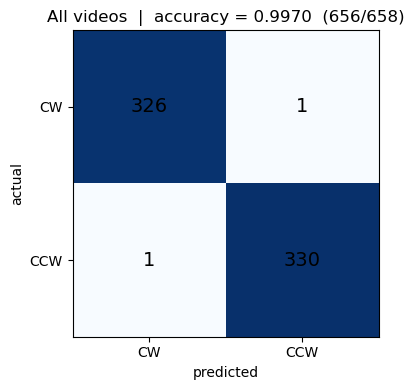

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(conf.values, cmap='Blues')
for i in range(conf.shape[0]):
    for j in range(conf.shape[1]):
        ax.text(j, i, int(conf.values[i, j]),
                ha='center', va='center', color='k', fontsize=14)
ax.set_xticks([0, 1]); ax.set_xticklabels(conf.columns)
ax.set_yticks([0, 1]); ax.set_yticklabels(conf.index)
ax.set_xlabel('predicted'); ax.set_ylabel('actual')
ax.set_title(f'All videos  |  accuracy = {accuracy:.4f}  ({n_correct}/{n_scored})')
plt.tight_layout()
heatmap_path = OUT_DIR / 'confusion_matrix.png'
plt.savefig(heatmap_path, dpi=130, bbox_inches='tight')
print(f'wrote: {heatmap_path}')
plt.show()